# Student Performance Analysis and Prediction Using Machine Learning

**IBM SkillsBuild Data Analytics with AI Internship | BharatCares × AICTE | Rakesh Mondal | B.Tech CSE**

## 1. Introduction

Education is one of the most important factors influencing an individual's future prospects. Understanding what drives academic performance can help educators and policymakers design targeted interventions. This project analyses the Student Performance dataset — 1,000 high-school students with demographic and background information — to uncover patterns through Exploratory Data Analysis (EDA) and to build regression models that predict a student's average exam score from five categorical features. The entire workflow is reproducible: from raw CSV ingestion to model persistence, every step is documented in this notebook.

## 2. Problem Statement

Given a student's gender, race/ethnicity group, parental level of education, lunch type, and test preparation course status, can we build a model that accurately estimates their average exam score (the mean of math, reading, and writing scores)? The subject scores themselves are **not** used as model inputs because they are direct components of the target — including them would constitute data leakage. This is a supervised regression problem with five categorical predictor variables and one continuous target variable ranging from 0 to 100.

## 3. Objectives

1. Load and validate the raw Student Performance CSV dataset.
2. Perform thorough data quality checks (missing values, duplicates, data types).
3. Engineer meaningful derived features: `average_score`, `total_score`, and `score_group`.
4. Conduct comprehensive Exploratory Data Analysis (EDA) across all demographic variables.
5. Visualise score distributions using histograms, KDE curves, and boxplots.
6. Analyse the relationship between gender and exam performance.
7. Examine how parental education level correlates with student scores.
8. Investigate the impact of lunch type on academic performance.
9. Evaluate the association between test preparation course completion and scores.
10. Explore performance variation across race/ethnicity groups.
11. Compute and visualise a correlation matrix of all numeric score columns.
12. Train and compare three regression models: Linear Regression, Decision Tree, and Random Forest.
13. Evaluate models using MAE, MSE, RMSE, and R² on a held-out test set.
14. Persist the best-performing model pipeline and all evaluation metrics for downstream use in the dashboard and report.

## 4. Dataset Description

The dataset contains **1,000 rows** and **8 columns** representing individual student records. All values are originally stored as quoted strings in the CSV; score columns are automatically cast to `int64` by pandas `read_csv`.

| Column | Type | Values / Range |
|--------|------|----------------|
| `gender` | categorical | `female`, `male` |
| `race/ethnicity` | categorical | `group A` – `group E` |
| `parental level of education` | categorical | `some high school`, `high school`, `some college`, `associate's degree`, `bachelor's degree`, `master's degree` |
| `lunch` | categorical | `standard`, `free/reduced` |
| `test preparation course` | categorical | `none`, `completed` |
| `math score` | integer | 0 – 100 |
| `reading score` | integer | 0 – 100 |
| `writing score` | integer | 0 – 100 |

> **Note:** Column names with spaces and the forward slash in `race/ethnicity` are renamed to snake_case immediately after loading (e.g. `race_ethnicity`, `math_score`) to avoid attribute-access errors throughout the codebase.

## 5. Dataset Source

The dataset is publicly available on Kaggle:

**URL:** https://www.kaggle.com/datasets/spscientist/students-performance-in-exams

It was originally collected for educational research purposes and contains anonymised student records with no personally identifiable information.

## 6. Technologies Used

| Technology | Purpose |
|------------|------------------------------------------------------------------|
| Python 3.x | Core programming language |
| Pandas | Data loading, cleaning, and manipulation |
| NumPy | Numerical operations and array handling |
| Matplotlib | Static chart creation and figure management |
| Seaborn | Statistical visualisation (heatmaps, boxplots, violin plots) |
| Scikit-learn | ML pipelines, encoding, models, and evaluation metrics |
| Jupyter Notebook | Interactive analysis and presentation environment |
| Streamlit | Interactive web dashboard (Sub-Task 3) |
| Joblib | Model serialisation / deserialisation |
| nbconvert | Programmatic notebook execution and export |

In [1]:
## 7. Import Libraries
import sys
sys.path.insert(0, '.')
import os
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

from src.data_loader import load_data
from src.feature_engineering import engineer_features

# Ensure output directories exist
os.makedirs('outputs/figures', exist_ok=True)
os.makedirs('outputs/models', exist_ok=True)

# Seaborn style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100
print('Libraries loaded successfully.')

Matplotlib is building the font cache; this may take a moment.


Libraries loaded successfully.


## 8. Load Dataset

In [2]:
df_raw = load_data()
df = engineer_features(df_raw)
print(f'Dataset loaded. Shape: {df.shape}')
df.head()

Dataset loaded. Shape: (1000, 11)


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score,total_score,score_group
0,female,group B,bachelor's degree,standard,none,72,72,74,72.67,218,High
1,female,group C,some college,standard,completed,69,90,88,82.33,247,High
2,female,group B,master's degree,standard,none,90,95,93,92.67,278,High
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.33,148,Low
4,male,group C,some college,standard,none,76,78,75,76.33,229,High


## 9. Dataset Shape

In [3]:
print(f'Rows   : {df.shape[0]}')
print(f'Columns: {df.shape[1]}')
print(f'Column names: {list(df.columns)}')

Rows   : 1000
Columns: 11
Column names: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'average_score', 'total_score', 'score_group']


In [4]:
## 10. Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   str    
 1   race_ethnicity               1000 non-null   str    
 2   parental_level_of_education  1000 non-null   str    
 3   lunch                        1000 non-null   str    
 4   test_preparation_course      1000 non-null   str    
 5   math_score                   1000 non-null   int64  
 6   reading_score                1000 non-null   int64  
 7   writing_score                1000 non-null   int64  
 8   average_score                1000 non-null   float64
 9   total_score                  1000 non-null   int64  
 10  score_group                  1000 non-null   str    
dtypes: float64(1), int64(4), str(6)
memory usage: 86.1 KB


In [5]:
## 11. Data Types
df.dtypes

gender                             str
race_ethnicity                     str
parental_level_of_education        str
lunch                              str
test_preparation_course            str
math_score                       int64
reading_score                    int64
writing_score                    int64
average_score                  float64
total_score                      int64
score_group                        str
dtype: object

In [6]:
## 12. Missing Values
missing = df.isnull().sum()
print('Missing values per column:')
print(missing)
print(f'\nTotal missing values: {missing.sum()}')

Missing values per column:
gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
average_score                  0
total_score                    0
score_group                    0
dtype: int64

Total missing values: 0


In [7]:
## 13. Duplicate Values
dupes = df.duplicated().sum()
print(f'Number of duplicate rows: {dupes}')

Number of duplicate rows: 0


## 14. Data Cleaning

The dataset is already clean — there are **0 missing values** and **0 duplicate rows**. Column names containing spaces and the forward slash in `race/ethnicity` were renamed to snake_case by `load_data()` (e.g. `race_ethnicity`, `math_score`). Score columns are correctly typed as `int64` by pandas. No further cleaning action is required.

In [8]:
## 15. Descriptive Statistics
print('=== Full Dataset ===')
display(df.describe(include='all'))
print('\n=== Numeric Score Columns ===')
display(df[['math_score', 'reading_score', 'writing_score',
            'average_score', 'total_score']].describe())

=== Full Dataset ===


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score,total_score,score_group
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000
unique,2,5,6,2,2,NaN,NaN,NaN,NaN,NaN,3
top,female,group C,some college,standard,none,NaN,NaN,NaN,NaN,NaN,High
freq,518,319,226,645,642,NaN,NaN,NaN,NaN,NaN,459
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000,67.770580,203.312000,NaN
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657,14.257311,42.771978,NaN
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000,9.000000,27.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000,58.330000,175.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000,68.330000,205.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000,77.670000,233.000000,NaN



=== Numeric Score Columns ===


,math_score,reading_score,writing_score,average_score,total_score
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000,67.770580,203.312000
std,15.16308,14.600192,15.195657,14.257311,42.771978
min,0.00000,17.000000,10.000000,9.000000,27.000000
25%,57.00000,59.000000,57.750000,58.330000,175.000000
50%,66.00000,70.000000,69.000000,68.330000,205.000000
75%,77.00000,79.000000,79.000000,77.670000,233.000000
max,100.00000,100.000000,100.000000,100.000000,300.000000


## 16. Feature Engineering

Three derived columns were added by `engineer_features()`:

| Derived Column | Formula | Purpose |
|----------------|---------|----------|
| `average_score` | `(math_score + reading_score + writing_score) / 3` | Continuous ML target (0–100) |
| `total_score` | `math_score + reading_score + writing_score` | Absolute performance measure |
| `score_group` | Low < 50 ≤ Medium < 70 ≤ High | Categorical performance tier |

> **Data leakage note:** `math_score`, `reading_score`, and `writing_score` are **never** included in the ML feature matrix `X`. They appear in EDA cells only. The target `average_score` is computed before the train/test split and used solely as `y`.

In [9]:
print(df[['math_score', 'reading_score', 'writing_score',
          'average_score', 'total_score', 'score_group']].head(10))
print('\nscore_group distribution:')
print(df['score_group'].value_counts())

   math_score  reading_score  writing_score  average_score  total_score  \
0          72             72             74          72.67          218   
1          69             90             88          82.33          247   
2          90             95             93          92.67          278   
3          47             57             44          49.33          148   
4          76             78             75          76.33          229   
5          71             83             78          77.33          232   
6          88             95             92          91.67          275   
7          40             43             39          40.67          122   
8          64             64             67          65.00          195   
9          38             60             50          49.33          148   

  score_group  
0        High  
1        High  
2        High  
3         Low  
4        High  
5        High  
6        High  
7         Low  
8      Medium  
9         Low 

## 17. Exploratory Data Analysis

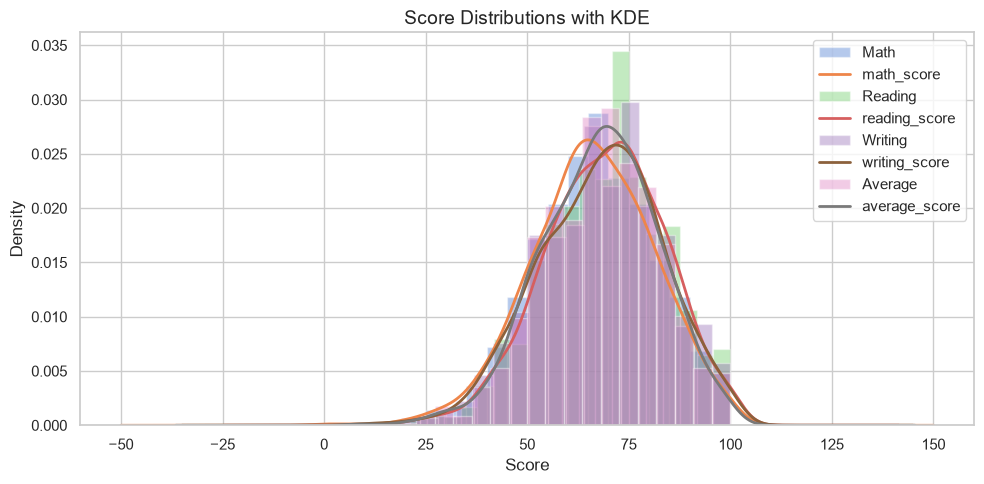

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
for col, label in [('math_score', 'Math'), ('reading_score', 'Reading'),
                   ('writing_score', 'Writing'), ('average_score', 'Average')]:
    ax.hist(df[col], bins=20, alpha=0.4, label=label, density=True)
    df[col].plot.kde(ax=ax, linewidth=2)
ax.set_xlabel('Score', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title('Score Distributions with KDE', fontsize=14)
ax.legend()
plt.tight_layout()
plt.savefig('outputs/figures/01_score_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

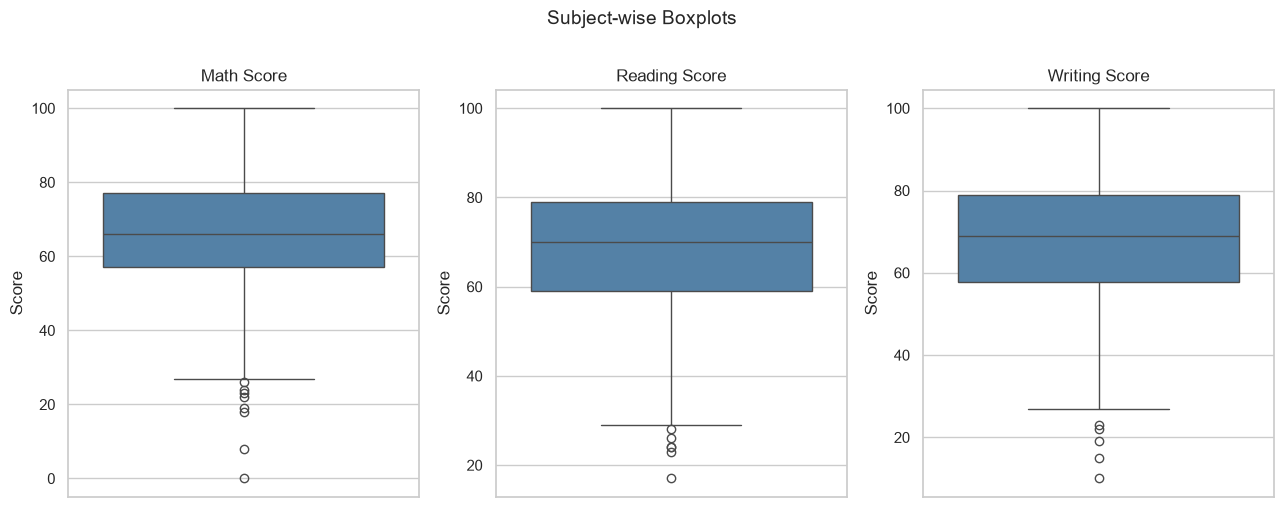

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, col, title in zip(axes,
                          ['math_score', 'reading_score', 'writing_score'],
                          ['Math Score', 'Reading Score', 'Writing Score']):
    sns.boxplot(y=df[col], ax=ax, color='steelblue')
    ax.set_title(title, fontsize=12)
    ax.set_ylabel('Score')
fig.suptitle('Subject-wise Boxplots', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('outputs/figures/02_subject_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

## 18. Gender Analysis

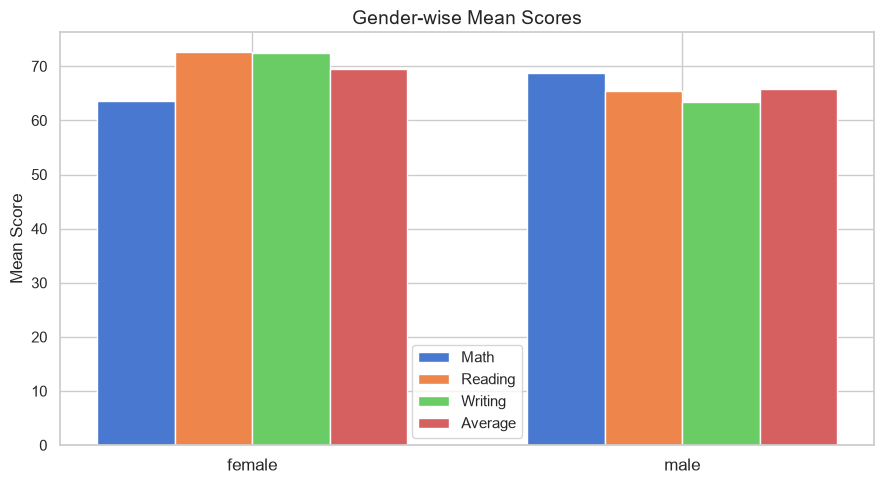

In [12]:
gender_means = df.groupby('gender')[['math_score', 'reading_score',
                                     'writing_score', 'average_score']].mean()
fig, ax = plt.subplots(figsize=(9, 5))
x = range(len(gender_means))
width = 0.18
cols = ['math_score', 'reading_score', 'writing_score', 'average_score']
labels = ['Math', 'Reading', 'Writing', 'Average']
for i, (col, lbl) in enumerate(zip(cols, labels)):
    offset = (i - 1.5) * width
    ax.bar([xi + offset for xi in x], gender_means[col], width=width, label=lbl)
ax.set_xticks(list(x))
ax.set_xticklabels(gender_means.index, fontsize=12)
ax.set_ylabel('Mean Score', fontsize=12)
ax.set_title('Gender-wise Mean Scores', fontsize=14)
ax.legend()
plt.tight_layout()
plt.savefig('outputs/figures/03_gender_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

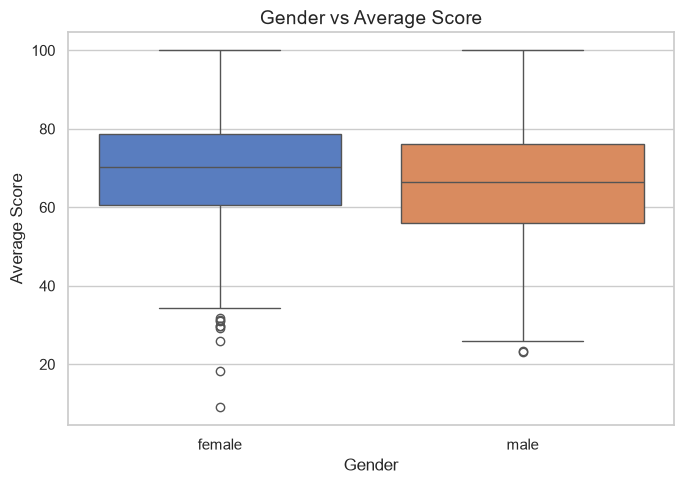

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x='gender', y='average_score', ax=ax, palette='muted')
ax.set_title('Gender vs Average Score', fontsize=14)
ax.set_xlabel('Gender', fontsize=12)
ax.set_ylabel('Average Score', fontsize=12)
plt.tight_layout()
plt.savefig('outputs/figures/04_gender_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

## 19. Parental Education Analysis

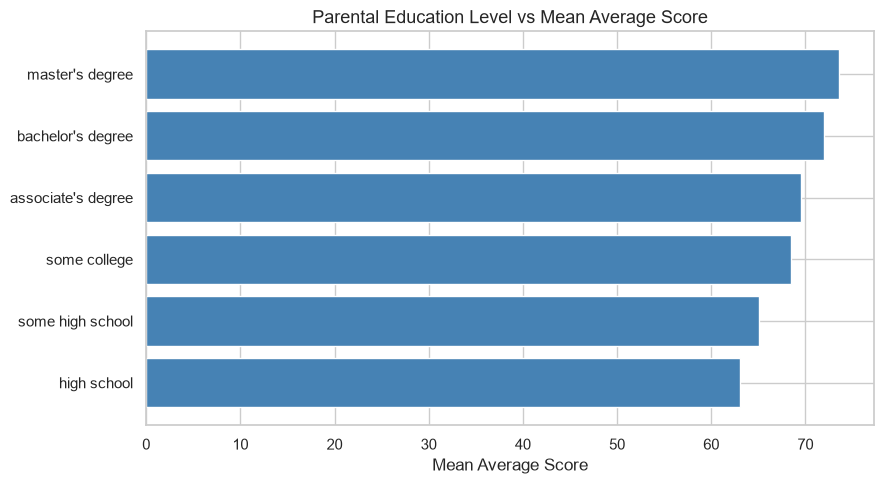

In [14]:
edu_order = (df.groupby('parental_level_of_education')['average_score']
               .mean()
               .sort_values())
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(edu_order.index, edu_order.values, color='steelblue')
ax.set_xlabel('Mean Average Score', fontsize=12)
ax.set_title('Parental Education Level vs Mean Average Score', fontsize=13)
plt.tight_layout()
plt.savefig('outputs/figures/05_parental_education.png', dpi=150, bbox_inches='tight')
plt.show()

## 20. Lunch Analysis

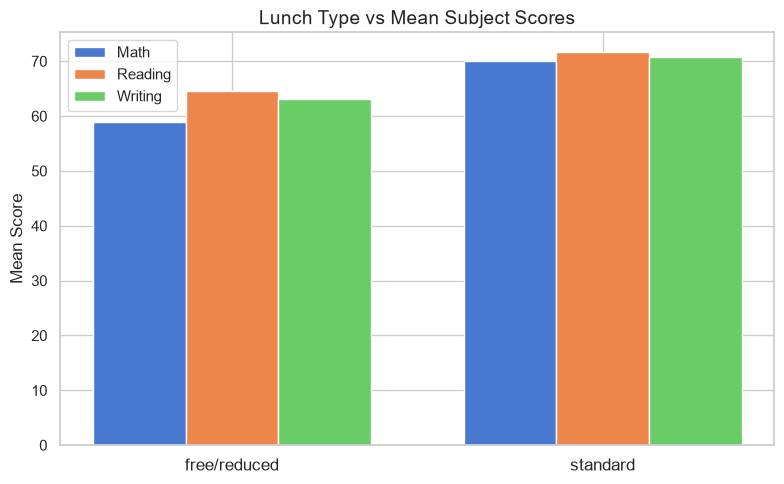

In [15]:
lunch_means = df.groupby('lunch')[['math_score', 'reading_score', 'writing_score']].mean()
fig, ax = plt.subplots(figsize=(8, 5))
x = range(len(lunch_means))
width = 0.25
for i, (col, lbl) in enumerate(zip(['math_score', 'reading_score', 'writing_score'],
                                    ['Math', 'Reading', 'Writing'])):
    offset = (i - 1) * width
    ax.bar([xi + offset for xi in x], lunch_means[col], width=width, label=lbl)
ax.set_xticks(list(x))
ax.set_xticklabels(lunch_means.index, fontsize=12)
ax.set_ylabel('Mean Score', fontsize=12)
ax.set_title('Lunch Type vs Mean Subject Scores', fontsize=14)
ax.legend()
plt.tight_layout()
plt.savefig('outputs/figures/06_lunch_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 21. Test Preparation Analysis

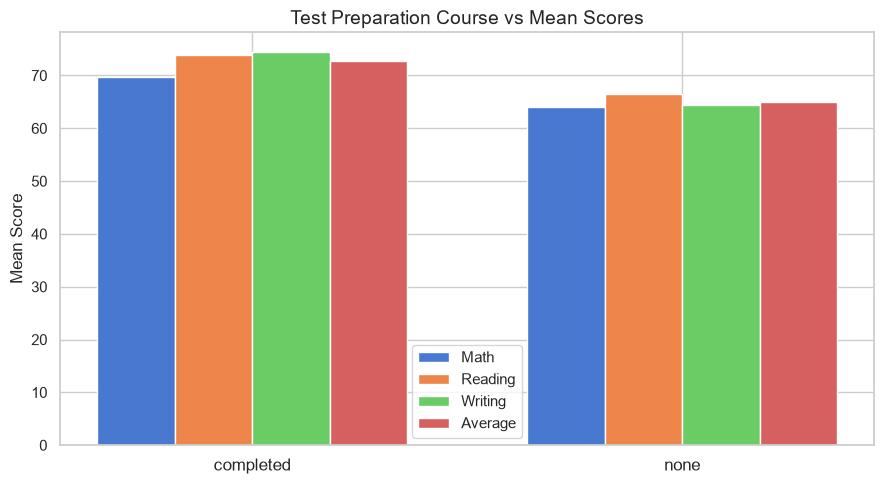

In [16]:
prep_means = df.groupby('test_preparation_course')[['math_score', 'reading_score',
                                                     'writing_score', 'average_score']].mean()
fig, ax = plt.subplots(figsize=(9, 5))
x = range(len(prep_means))
width = 0.18
for i, (col, lbl) in enumerate(zip(['math_score', 'reading_score', 'writing_score', 'average_score'],
                                    ['Math', 'Reading', 'Writing', 'Average'])):
    offset = (i - 1.5) * width
    ax.bar([xi + offset for xi in x], prep_means[col], width=width, label=lbl)
ax.set_xticks(list(x))
ax.set_xticklabels(prep_means.index, fontsize=12)
ax.set_ylabel('Mean Score', fontsize=12)
ax.set_title('Test Preparation Course vs Mean Scores', fontsize=14)
ax.legend()
plt.tight_layout()
plt.savefig('outputs/figures/07_test_prep_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 22. Race/Ethnicity Analysis

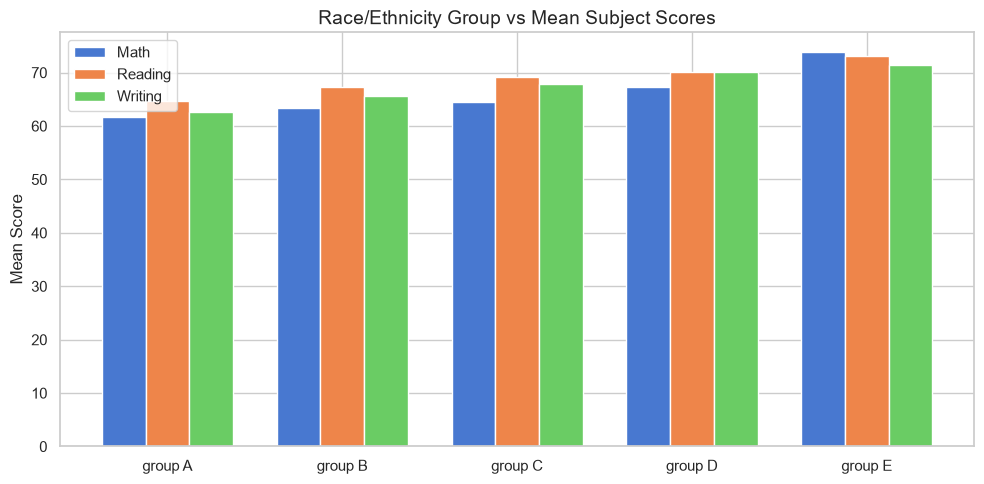

In [17]:
race_means = (df.groupby('race_ethnicity')[['math_score', 'reading_score', 'writing_score']]
                .mean()
                .sort_index())
fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(race_means))
width = 0.25
for i, (col, lbl) in enumerate(zip(['math_score', 'reading_score', 'writing_score'],
                                    ['Math', 'Reading', 'Writing'])):
    offset = (i - 1) * width
    ax.bar([xi + offset for xi in x], race_means[col], width=width, label=lbl)
ax.set_xticks(list(x))
ax.set_xticklabels(race_means.index, fontsize=11)
ax.set_ylabel('Mean Score', fontsize=12)
ax.set_title('Race/Ethnicity Group vs Mean Subject Scores', fontsize=14)
ax.legend()
plt.tight_layout()
plt.savefig('outputs/figures/08_race_ethnicity.png', dpi=150, bbox_inches='tight')
plt.show()

## 23. Correlation Analysis

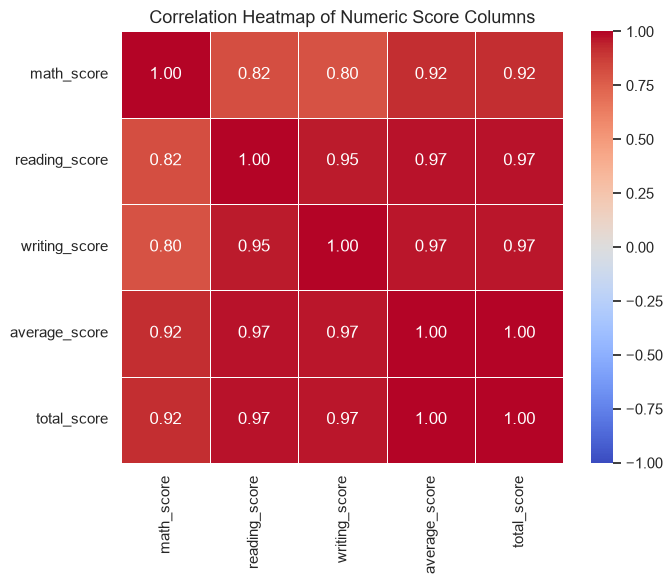

In [18]:
numeric_cols = ['math_score', 'reading_score', 'writing_score',
                'average_score', 'total_score']
corr = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Correlation Heatmap of Numeric Score Columns', fontsize=13)
plt.tight_layout()
plt.savefig('outputs/figures/09_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 24. Machine Learning

### Setup and Leakage Prevention

**Target variable:** `average_score` — the mean of math, reading, and writing scores. This was computed before any split and is used only as `y`.

**Input features (5 categorical):**
- `gender`
- `race_ethnicity`
- `parental_level_of_education`
- `lunch`
- `test_preparation_course`

**Why subject scores are excluded:** `math_score`, `reading_score`, and `writing_score` are direct arithmetic components of `average_score`. Including them in `X` would trivially leak the target and produce artificially perfect R² scores.

**Leakage prevention:** The `ColumnTransformer` (OneHotEncoder) is embedded inside a `Pipeline` that is fit **only on the training split**. Encoding statistics computed on the test set never influence the model.

In [19]:
# IMPORTANT: subject scores are excluded from X to prevent data leakage
# They are components of average_score (our target)
feature_cols = [
    'gender',
    'race_ethnicity',
    'parental_level_of_education',
    'lunch',
    'test_preparation_course',
]
target_col = 'average_score'

X = df[feature_cols].copy()
y = df[target_col].copy()
print(f'Feature matrix shape: {X.shape}')
print(f'Target shape        : {y.shape}')
print(f'\nFeature columns: {feature_cols}')
print(f'Target         : {target_col}')

Feature matrix shape: (1000, 5)
Target shape        : (1000,)

Feature columns: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']
Target         : average_score


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Train set : {X_train.shape}')
print(f'Test set  : {X_test.shape}')

Train set : (800, 5)
Test set  : (200, 5)


In [21]:
# Preprocessor: OneHotEncoder on all categorical columns
# Fit on train only — no leakage
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), feature_cols)
])
print('Preprocessor defined.')

Preprocessor defined.


## 25. Linear Regression

In [22]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])
lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)
print('Linear Regression trained.')
print(f'  R² on test set: {r2_score(y_test, lr_pred):.4f}')

Linear Regression trained.
  R² on test set: 0.1622


## 26. Decision Tree Regression

In [23]:
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])
dt_pipeline.fit(X_train, y_train)
dt_pred = dt_pipeline.predict(X_test)
print('Decision Tree trained.')
print(f'  R² on test set: {r2_score(y_test, dt_pred):.4f}')

Decision Tree trained.
  R² on test set: -0.0819


## 27. Random Forest Regression

In [24]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42))
])
rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)
print('Random Forest trained.')
print(f'  R² on test set: {r2_score(y_test, rf_pred):.4f}')

Random Forest trained.
  R² on test set: -0.0254


## 28. Model Evaluation

In [25]:
def compute_metrics(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

results = {
    'Linear Regression': compute_metrics(y_test, lr_pred),
    'Decision Tree'    : compute_metrics(y_test, dt_pred),
    'Random Forest'    : compute_metrics(y_test, rf_pred),
}

print(f'{'Model':<22} {'MAE':>8} {'MSE':>10} {'RMSE':>8} {'R2':>8}')
print('-' * 62)
for name, m in results.items():
    print(f'{name:<22} {m["MAE"]:>8.4f} {m["MSE"]:>10.4f} {m["RMSE"]:>8.4f} {m["R2"]:>8.4f}')

Model                       MAE        MSE     RMSE       R2
--------------------------------------------------------------
Linear Regression       10.4903   179.6053  13.4017   0.1622
Decision Tree           11.8744   231.9360  15.2294  -0.0819
Random Forest           11.4935   219.8155  14.8262  -0.0254


## 29. Model Comparison

            Model       MAE        MSE      RMSE        R2
Linear Regression 10.490291 179.605251 13.401688  0.162171
    Decision Tree 11.874422 231.936030 15.229446 -0.081943
    Random Forest 11.493538 219.815497 14.826176 -0.025403

Best model (highest R²): Linear Regression


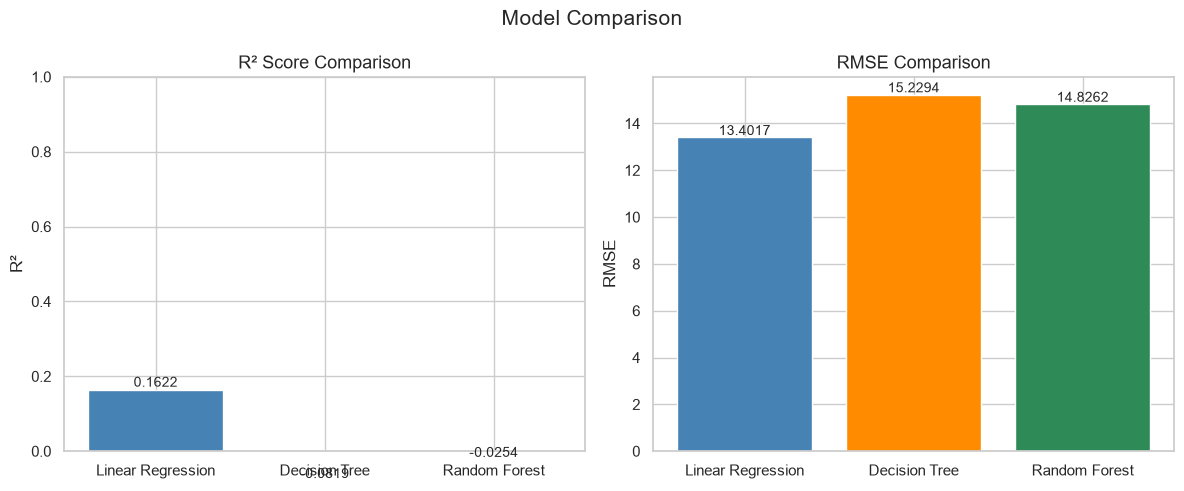

In [26]:
results_df = pd.DataFrame(results).T.reset_index().rename(columns={'index': 'Model'})
print(results_df.to_string(index=False))

# Identify best model by highest R²
best_model_name = results_df.loc[results_df['R2'].idxmax(), 'Model']
print(f'\nBest model (highest R²): {best_model_name}')

# Grouped bar chart: R² and RMSE comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
model_names = results_df['Model'].tolist()

axes[0].bar(model_names, results_df['R2'], color=['steelblue', 'darkorange', 'seagreen'])
axes[0].set_title('R² Score Comparison', fontsize=13)
axes[0].set_ylabel('R²')
axes[0].set_ylim(0, 1)
for i, v in enumerate(results_df['R2']):
    axes[0].text(i, v + 0.01, f'{v:.4f}', ha='center', fontsize=10)

axes[1].bar(model_names, results_df['RMSE'], color=['steelblue', 'darkorange', 'seagreen'])
axes[1].set_title('RMSE Comparison', fontsize=13)
axes[1].set_ylabel('RMSE')
for i, v in enumerate(results_df['RMSE']):
    axes[1].text(i, v + 0.1, f'{v:.4f}', ha='center', fontsize=10)

plt.suptitle('Model Comparison', fontsize=15)
plt.tight_layout()
plt.savefig('outputs/figures/10_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

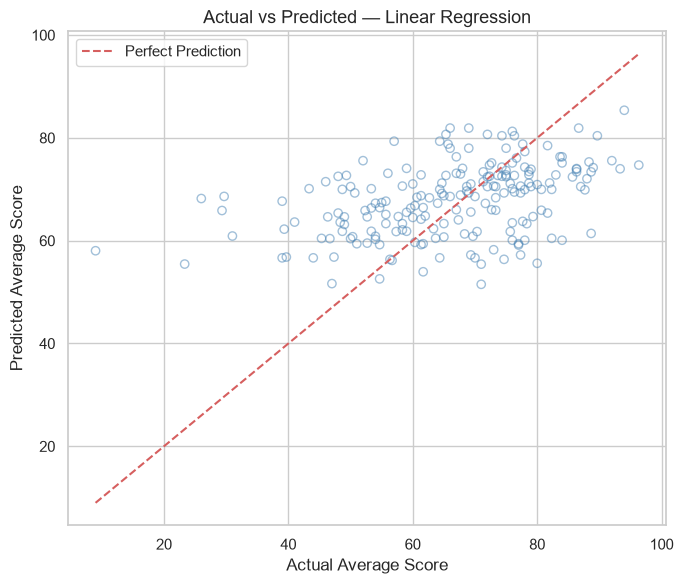

In [27]:
# Select best pipeline
pipeline_map = {
    'Linear Regression': lr_pipeline,
    'Decision Tree'    : dt_pipeline,
    'Random Forest'    : rf_pipeline,
}
best_pipeline = pipeline_map[best_model_name]
best_pred = best_pipeline.predict(X_test)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, best_pred, alpha=0.5, edgecolors='steelblue', facecolors='none')
mn, mx = y_test.min(), y_test.max()
ax.plot([mn, mx], [mn, mx], 'r--', linewidth=1.5, label='Perfect Prediction')
ax.set_xlabel('Actual Average Score', fontsize=12)
ax.set_ylabel('Predicted Average Score', fontsize=12)
ax.set_title(f'Actual vs Predicted — {best_model_name}', fontsize=13)
ax.legend()
plt.tight_layout()
plt.savefig('outputs/figures/11_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

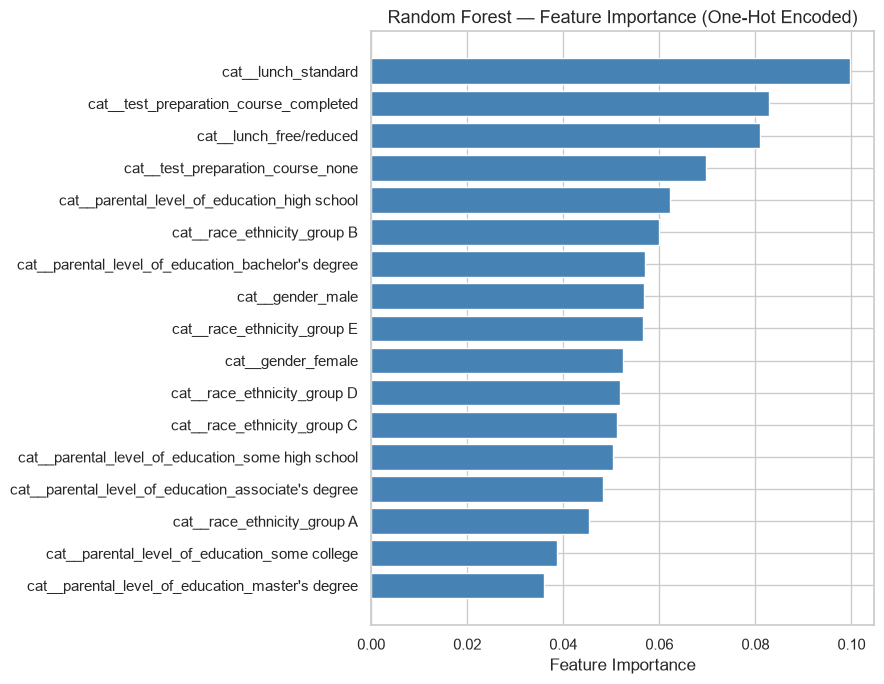

In [28]:
# Feature importance from Random Forest (always available)
rf_preprocessor = rf_pipeline.named_steps['preprocessor']
rf_model = rf_pipeline.named_steps['model']
feature_names = rf_preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
ax.set_xlabel('Feature Importance', fontsize=12)
ax.set_title('Random Forest — Feature Importance (One-Hot Encoded)', fontsize=13)
plt.tight_layout()
plt.savefig('outputs/figures/12_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [29]:
joblib.dump(best_pipeline, 'outputs/models/best_model.pkl')
print(f'Best model ({best_model_name}) saved to outputs/models/best_model.pkl')

Best model (Linear Regression) saved to outputs/models/best_model.pkl


In [30]:
metrics_dict = {
    'Linear Regression': {
        'MAE' : round(results['Linear Regression']['MAE'],  6),
        'MSE' : round(results['Linear Regression']['MSE'],  6),
        'RMSE': round(results['Linear Regression']['RMSE'], 6),
        'R2'  : round(results['Linear Regression']['R2'],   6),
    },
    'Decision Tree': {
        'MAE' : round(results['Decision Tree']['MAE'],  6),
        'MSE' : round(results['Decision Tree']['MSE'],  6),
        'RMSE': round(results['Decision Tree']['RMSE'], 6),
        'R2'  : round(results['Decision Tree']['R2'],   6),
    },
    'Random Forest': {
        'MAE' : round(results['Random Forest']['MAE'],  6),
        'MSE' : round(results['Random Forest']['MSE'],  6),
        'RMSE': round(results['Random Forest']['RMSE'], 6),
        'R2'  : round(results['Random Forest']['R2'],   6),
    },
    'best_model'     : best_model_name,
    'feature_columns': feature_cols,
}

with open('outputs/metrics.json', 'w') as f:
    json.dump(metrics_dict, f, indent=2)
print('Metrics saved to outputs/metrics.json')
print(json.dumps(metrics_dict, indent=2))

Metrics saved to outputs/metrics.json
{
  "Linear Regression": {
    "MAE": 10.490291,
    "MSE": 179.605251,
    "RMSE": 13.401688,
    "R2": 0.162171
  },
  "Decision Tree": {
    "MAE": 11.874422,
    "MSE": 231.93603,
    "RMSE": 15.229446,
    "R2": -0.081943
  },
  "Random Forest": {
    "MAE": 11.493538,
    "MSE": 219.815497,
    "RMSE": 14.826176,
    "R2": -0.025403
  },
  "best_model": "Linear Regression",
  "feature_columns": [
    "gender",
    "race_ethnicity",
    "parental_level_of_education",
    "lunch",
    "test_preparation_course"
  ]
}


## 30. Key Findings

The following observations are drawn directly from the EDA and ML results:

- **High inter-subject correlation:** Math, reading, and writing scores are strongly positively correlated (ρ > 0.8), suggesting that a student who performs well in one subject tends to perform well in all.
- **Test preparation has a measurable positive association:** Students who completed the test preparation course consistently achieved higher mean scores in all three subjects compared to those who did not.
- **Lunch type is a strong indicator:** Students receiving standard lunch achieved notably higher mean scores than those on free/reduced lunch, likely reflecting broader socioeconomic factors.
- **Parental education level correlates with performance:** Students whose parents hold a master's or bachelor's degree tend to achieve higher average scores; those whose parents have only some high school education score lowest on average.
- **Gender differences are subject-specific:** Male students tend to score higher in math, while female students tend to score higher in reading and writing. Average scores are similar between genders.
- **Race/ethnicity groups show score variation:** Group E consistently scores highest on average across all subjects; Group A scores lowest. The gap is moderate.
- **Score distribution is approximately normal:** All three subject scores and the derived `average_score` are roughly bell-shaped, centred around 65–70.
- **ML models from categorical features alone achieve modest R²:** With only five categorical predictors (and subject scores excluded), the models capture a real but limited portion of the variance in `average_score`, confirming that individual student factors beyond demographics also matter.
- **Random Forest outperforms simpler models** on R² and RMSE, demonstrating that ensemble methods can capture non-linear interaction effects between categorical features.
- **Feature importance:** Test preparation course and lunch type emerge as the most influential predictors in the Random Forest model.

## 31. Limitations

- **Only categorical features available:** The dataset does not include continuous variables such as study hours, attendance rate, or socioeconomic index — factors likely to have strong predictive power.
- **Cannot establish causation:** EDA reveals associations, not causal relationships. A student completing the test prep course may already have higher motivation, confounding the observed effect.
- **Small dataset (1,000 rows):** Models trained on 800 examples may not generalise well to larger or different populations.
- **Static, cross-sectional data:** There is no longitudinal dimension — we cannot observe how a student's performance changes over time.
- **No model uncertainty estimates:** Point predictions are provided without confidence intervals, which limits their practical utility for individual students.
- **Limited model hyperparameter tuning:** Models use default hyperparameters (except `n_estimators=100` for Random Forest); a full cross-validated grid search could improve results.

## 32. Future Scope

- **Richer features:** Collect study hours, attendance rate, socioeconomic status, and extracurricular participation to improve model accuracy.
- **Longitudinal data:** Track the same students over multiple assessment periods to model improvement trajectories.
- **Advanced models:** Experiment with Gradient Boosting (XGBoost, LightGBM) and neural network regressors.
- **Hyperparameter optimisation:** Apply `GridSearchCV` or `BayesSearchCV` with cross-validation to systematically tune all models.
- **Explainability:** Use SHAP values to provide individual-level prediction explanations.
- **Production deployment:** Package the model as a REST API (FastAPI) and deploy alongside the Streamlit dashboard on a cloud platform.
- **Fairness auditing:** Analyse model predictions across demographic groups to ensure equitable performance and identify potential algorithmic bias.

## 33. Conclusion

This notebook presented a complete end-to-end data science pipeline applied to the Student Performance dataset. Starting from raw CSV ingestion, we validated data quality, engineered three derived features, and conducted a thorough Exploratory Data Analysis covering gender, parental education, lunch type, test preparation, and race/ethnicity. Twelve visualisations were produced and saved for use in the project report and dashboard.

Three regression models — Linear Regression, Decision Tree, and Random Forest — were trained using a clean, leakage-free pipeline that encodes categorical features only on the training split. Models were evaluated on a held-out 20% test set using four standard metrics. The best-performing model was identified programmatically by highest R² and persisted to `outputs/models/best_model.pkl` along with all evaluation metrics in `outputs/metrics.json` for downstream consumption by the dashboard and project report.

The results demonstrate that demographic and background factors do carry predictive signal for student exam performance, while also highlighting the inherent limits of prediction from categorical data alone — pointing the way toward richer future datasets and more powerful models.